In [28]:
import numpy as np
import matplotlib.pyplot as plt

In [29]:
# Define camera resolution
resolution_x = 32
resolution_y = 24

# The total number of thermal readings
total_readings = resolution_x * resolution_y

# --- INGRESA TUS 768 NÚMEROS TÉRMICOS AQUÍ ---
# Se te pedirá que ingreses los números en un cuadro de texto.
# Asegúrate de que sean exactamente 768 números, separados por comas o espacios.

thermal_input_string = input(f"Por favor, ingresa los {total_readings} números térmicos separados por comas o espacios: ")

# Convertir la cadena de texto a una lista de números flotantes
try:
    # First, replace all commas with spaces to treat both as delimiters
    processed_input = thermal_input_string.replace(',', ' ')
    # Then, split by any whitespace and convert non-empty parts to floats
    thermal_numbers_list = [float(num) for num in processed_input.split() if num]
except ValueError:
    raise ValueError("Error al convertir los datos. Asegúrate de que todos los valores sean números válidos separados por comas o espacios.")

# Asigna tus números a la variable que se usará para el procesamiento
simulated_thermal_numbers = np.array(thermal_numbers_list)

# Asegurarse de que el número de lecturas coincida con el total esperado
if len(simulated_thermal_numbers) != total_readings:
    raise ValueError(f"Se esperaban {total_readings} lecturas térmicas, pero se recibieron {len(simulated_thermal_numbers)}.")

print(f"Cargadas {len(simulated_thermal_numbers)} lecturas térmicas.")

Por favor, ingresa los 768 números térmicos separados por comas o espacios: 28.4,28.8,29.0,28.8,29.0,28.9,28.8,29.2,29.8,29.8,29.6,30.2,30.1,29.9,29.8,30.0,30.0,30.0,29.7,30.1,30.3,30.3,29.8,30.1,30.5,30.5,30.6,31.1,31.0,30.5,27.8,28.2 28.8,29.0,29.4,28.5,28.5,28.6,28.8,28.2,28.8,29.2,29.3,28.6,29.1,29.3,29.1,28.7,29.5,29.1,29.1,29.1,29.6,29.6,29.5,29.4,29.8,30.1,30.2,30.3,30.8,31.0,28.4,27.1 29.1,28.1,28.6,28.2,28.4,27.8,27.7,28.1,28.2,28.1,27.7,27.9,27.9,28.0,27.6,28.2,28.0,28.0,27.4,28.1,28.1,28.0,27.6,28.3,28.8,28.6,28.7,29.4,29.3,29.3,28.3,28.1 29.0,28.5,28.3,27.6,28.1,28.0,27.6,27.1,28.0,28.1,27.7,27.4,27.9,28.2,28.5,27.9,28.2,27.9,27.9,27.1,27.6,27.7,27.4,27.0,27.9,28.1,28.1,27.8,28.1,28.5,27.3,26.9 28.4,27.6,27.8,27.7,27.8,27.8,27.6,28.1,28.0,27.7,27.7,28.0,28.8,29.9,29.5,30.4,28.5,28.2,27.6,28.3,27.7,27.6,26.8,27.1,27.3,26.9,26.8,27.1,26.8,26.6,26.5,26.9 28.0,27.9,28.0,27.1,27.8,27.8,27.8,27.1,27.9,28.2,28.1,27.8,30.1,29.9,30.3,30.5,30.1,28.2,28.4,28.0,28.3,27.5,27.2,26.6,27.2

In [30]:
# Reshape the 1D array into a 2D array (32x24)
thermal_image_data = simulated_thermal_numbers.reshape(resolution_y, resolution_x)

print(f"Reshaped data into a {thermal_image_data.shape} array.")


Reshaped data into a (24, 32) array.


In [31]:
from scipy.ndimage import gaussian_filter

# Apply a Gaussian filter for smoothing
# Adjust 'sigma' to control the degree of smoothing. A higher sigma means more blurring.
sigma = 3.0 # Set to a lower value for less smoothing
smoothed_thermal_image_data = gaussian_filter(thermal_image_data, sigma=sigma)

print(f"Data smoothed with a Gaussian filter (sigma={sigma}).")

Data smoothed with a Gaussian filter (sigma=3.0).


Procesando imagen térmica con:
- Zoom factor: 1.15
Dimensiones originales: (24, 32)
Nuevas dimensiones después del zoom: (27.599999999999998, 36.8)


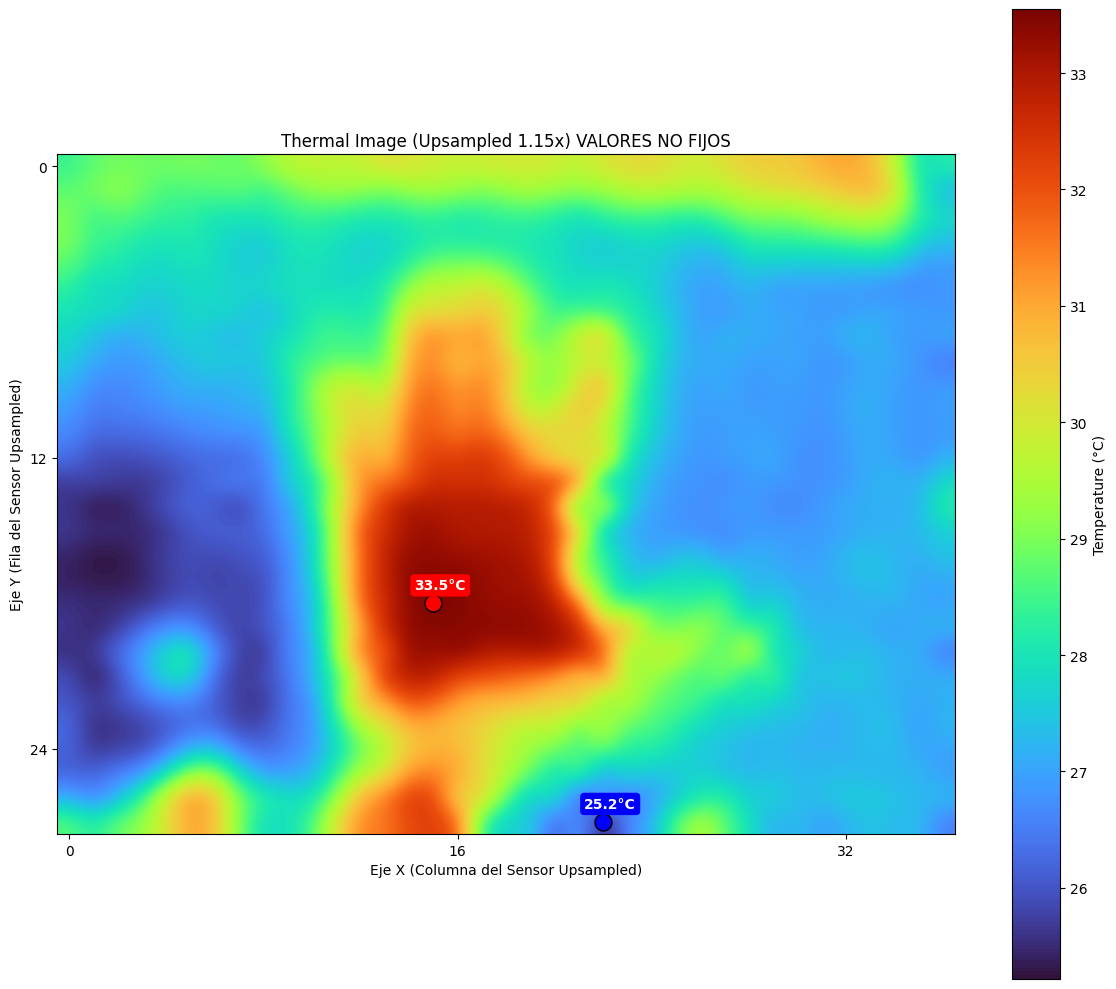

In [34]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import zoom

# --- Parámetros de ajuste ---
zoom_factor = 1  # Factor de aumento de resolución

print(f"Procesando imagen térmica con:\n- Zoom factor: {zoom_factor}")

# Calcular las nuevas resoluciones para la imagen interpolada
new_resolution_y = thermal_image_data.shape[0] * zoom_factor
new_resolution_x = thermal_image_data.shape[1] * zoom_factor

print(f"Dimensiones originales: {thermal_image_data.shape}")
print(f"Nuevas dimensiones después del zoom: ({new_resolution_y}, {new_resolution_x})")

# 1. Upsample los datos térmicos directamente sin suavizado previo ni posterior
# Esto genera más puntos de datos basados en los existentes usando interpolación bilineal.
upsampled_thermal_data = zoom(thermal_image_data, zoom=zoom_factor, order=1)
#print(f"Datos upsampled {zoom_factor}x.")

# Encontrar los valores y ubicaciones de temperatura máxima y mínima en los datos upsampled
max_temp_upsampled = np.max(upsampled_thermal_data)
min_temp_upsampled = np.min(upsampled_thermal_data)
max_loc_upsampled = np.unravel_index(np.argmax(upsampled_thermal_data), upsampled_thermal_data.shape)
min_loc_upsampled = np.unravel_index(np.argmin(upsampled_thermal_data), upsampled_thermal_data.shape)

# Calcular el promedio y el rango de los datos upsampled
avg_temp_upsampled = np.mean(upsampled_thermal_data)
temp_range_upsampled = max_temp_upsampled - min_temp_upsampled

# 2. Visualizar la nueva imagen térmica upsampled
plt.figure(figsize=(12, 10)) # Aumentar el tamaño de la figura para acomodar el texto

plt.imshow(upsampled_thermal_data, cmap="turbo", interpolation='bicubic') #AQUI VA EL COLORMAP

plt.colorbar(label='Temperature (°C)') # Restablecer la etiqueta de la barra de color
plt.title(f'Thermal Image (Upsampled {zoom_factor}x) VALORES NO FIJOS') # Título actualizado
plt.xlabel('Eje X (Columna del Sensor Upsampled)')
plt.ylabel('Eje Y (Fila del Sensor Upsampled)')

# Ajustar los ticks para la nueva resolución
plt.xticks(np.arange(0, new_resolution_x, resolution_x // 2))
plt.yticks(np.arange(0, new_resolution_y, resolution_y // 2))

# Marcar puntos max y min en la imagen upsampled
plt.scatter(max_loc_upsampled[1], max_loc_upsampled[0], marker='o', color='red', s=150, edgecolors='black', linewidth=1, label=f'Max: {max_temp_upsampled:.1f}°C')
plt.scatter(min_loc_upsampled[1], min_loc_upsampled[0], marker='o', color='blue', s=150, edgecolors='black', linewidth=1, label=f'Min: {min_temp_upsampled:.1f}°C')

# Anotar los valores de max y min en la imagen upsampled
plt.annotate(f'{max_temp_upsampled:.1f}°C', (max_loc_upsampled[1], max_loc_upsampled[0]), textcoords="offset points", xytext=(5,10), ha='center', color='white', fontsize=10, fontweight='bold', bbox=dict(boxstyle="round,pad=0.3", fc="red", ec="none", lw=0))
plt.annotate(f'{min_temp_upsampled:.1f}°C', (min_loc_upsampled[1], min_loc_upsampled[0]), textcoords="offset points", xytext=(5,10), ha='center', color='white', fontsize=10, fontweight='bold', bbox=dict(boxstyle="round,pad=0.3", fc="blue", ec="none", lw=0))

# Mostrar información adicional a un costado
#plt.text(0.85, 0.95, f'Average: {avg_temp_upsampled:.2f}°C', transform=plt.gca().transAxes, fontsize=12, verticalalignment='top', bbox=dict(boxstyle='round,pad=0.3', fc='yellow', ec='k', lw=1, alpha=0.6))
#plt.text(0.85, 0.88, f'Range: {temp_range_upsampled:.2f}°C', transform=plt.gca().transAxes, fontsize=12, verticalalignment='top', bbox=dict(boxstyle='round,pad=0.3', fc='yellow', ec='k', lw=1, alpha=0.6))

plt.tight_layout() # Ajustar el diseño para evitar que el texto se superponga
plt.show()